In [1]:
# загружаем необходимые библиотеки
import pandas as pd
import numpy as np

from scipy import stats
import statsmodels.api as sm
from statsmodels import stats as sms

import matplotlib.pyplot as plt
import seaborn as sns

# загружаем датасет
data = pd.read_csv('ds_salaries.csv', index_col=0)
data.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L


Выяснить, какие факторы влияют на зарплату специалиста Data Scientist. 

А также ответить на ключевые вопросы HR-агентства:

Наблюдается ли ежегодный рост зарплат у специалистов Data Scientist?

Как соотносятся зарплаты Data Scientist и Data Engineer в 2022 году?

Как соотносятся зарплаты специалистов Data Scientist в компаниях различных размеров?

Есть ли связь между наличием должностей Data Scientist и Data Engineer и размером компании?

Если вы найдёте в данных интересные закономерности, также отметьте их в своём анализе.

Продемонстрируйте использование разных тестов для проверки статистической значимости сделанных выводов:

тесты для количественного признака:

для одной выборки;

для двух выборок;

для нескольких выборок;


In [2]:
# задаём уровень значимости
alpha = 0.05 
print("Уровень значимости alpha = {:.2f}".format(alpha))



Уровень значимости alpha = 0.05


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 607 entries, 0 to 606
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           607 non-null    int64 
 1   experience_level    607 non-null    object
 2   employment_type     607 non-null    object
 3   job_title           607 non-null    object
 4   salary              607 non-null    int64 
 5   salary_currency     607 non-null    object
 6   salary_in_usd       607 non-null    int64 
 7   employee_residence  607 non-null    object
 8   remote_ratio        607 non-null    int64 
 9   company_location    607 non-null    object
 10  company_size        607 non-null    object
dtypes: int64(4), object(7)
memory usage: 56.9+ KB


In [4]:
print('Количество дубликатов: {}'.format(data[data.duplicated()].shape[0]))
# Удаляем дубликаты:
data = data.drop_duplicates()
print('Размер таблицы после удаления дубликатов: {}'.format(data.shape))

Количество дубликатов: 42
Размер таблицы после удаления дубликатов: (565, 11)


In [5]:
# Чистые данные 
# Удалить salary и salary_currency
data = data.drop(['salary','salary_currency'],axis = 1)

In [6]:
data.head()

,work_year,experience_level,employment_type,job_title,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2020,MI,FT,Data Scientist,79833,DE,0,DE,L
1,2020,SE,FT,Machine Learning Scientist,260000,JP,0,JP,S
2,2020,SE,FT,Big Data Engineer,109024,GB,50,GB,M
3,2020,MI,FT,Product Data Analyst,20000,HN,0,HN,S
4,2020,SE,FT,Machine Learning Engineer,150000,US,50,US,L


In [7]:
ds = data[data['job_title'] == 'Data Scientist']
ds.shape

(130, 9)

In [8]:
ds.head()

,work_year,experience_level,employment_type,job_title,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2020,MI,FT,Data Scientist,79833,DE,0,DE,L
7,2020,MI,FT,Data Scientist,35735,HU,50,HU,L
10,2020,EN,FT,Data Scientist,51321,FR,0,FR,S
11,2020,MI,FT,Data Scientist,40481,IN,0,IN,L
12,2020,EN,FT,Data Scientist,39916,FR,0,FR,M


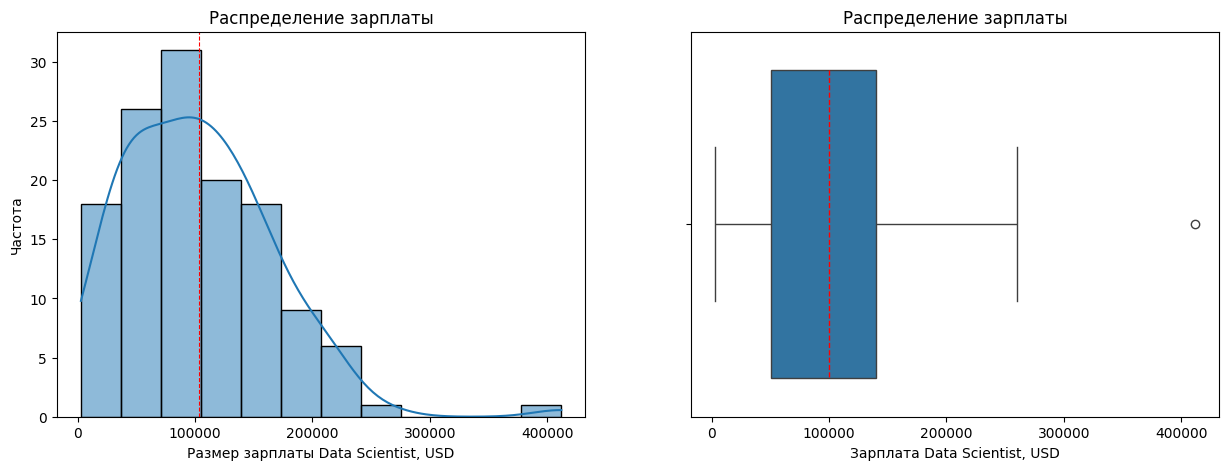

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(ds['salary_in_usd'], kde=True, ax=axes[0])
axes[0].set(xlabel='Размер зарплаты Data Scientist, USD', ylabel='Частота')
axes[0].set_title('Распределение зарплаты')
axes[0].axvline(ds['salary_in_usd'].mean(), color='red', linestyle='--', linewidth=0.8)

sns.boxplot(ds['salary_in_usd'], ax=axes[1], orient='h', medianprops={"color": "red", "linestyle": '--'})
axes[1].set(xlabel='Зарплата Data Scientist, USD', ylabel='')
axes[1].set_title('Распределение зарплаты')

plt.show()

Распределение смещено вправо, основная масса зарплат в диапозоне от 50.000 до 150.000 Это не нормальное распределение.
Одна точка далеко справо больше 400.000
Среднее и медиана около 100.000 
 При скошенных данных типичную         
    зарплату лучше описывает медиана
    
                                               
                                                                                      

work_year
2022    65
2021    44
2020    21
Name: count, dtype: int64
experience_level
MI    59
SE    49
EN    22
Name: count, dtype: int64
company_size
M    66
L    43
S    21
Name: count, dtype: int64
remote_ratio
100    68
0      38
50     24
Name: count, dtype: int64
employment_type
FT    127
PT      2
FL      1
Name: count, dtype: int64


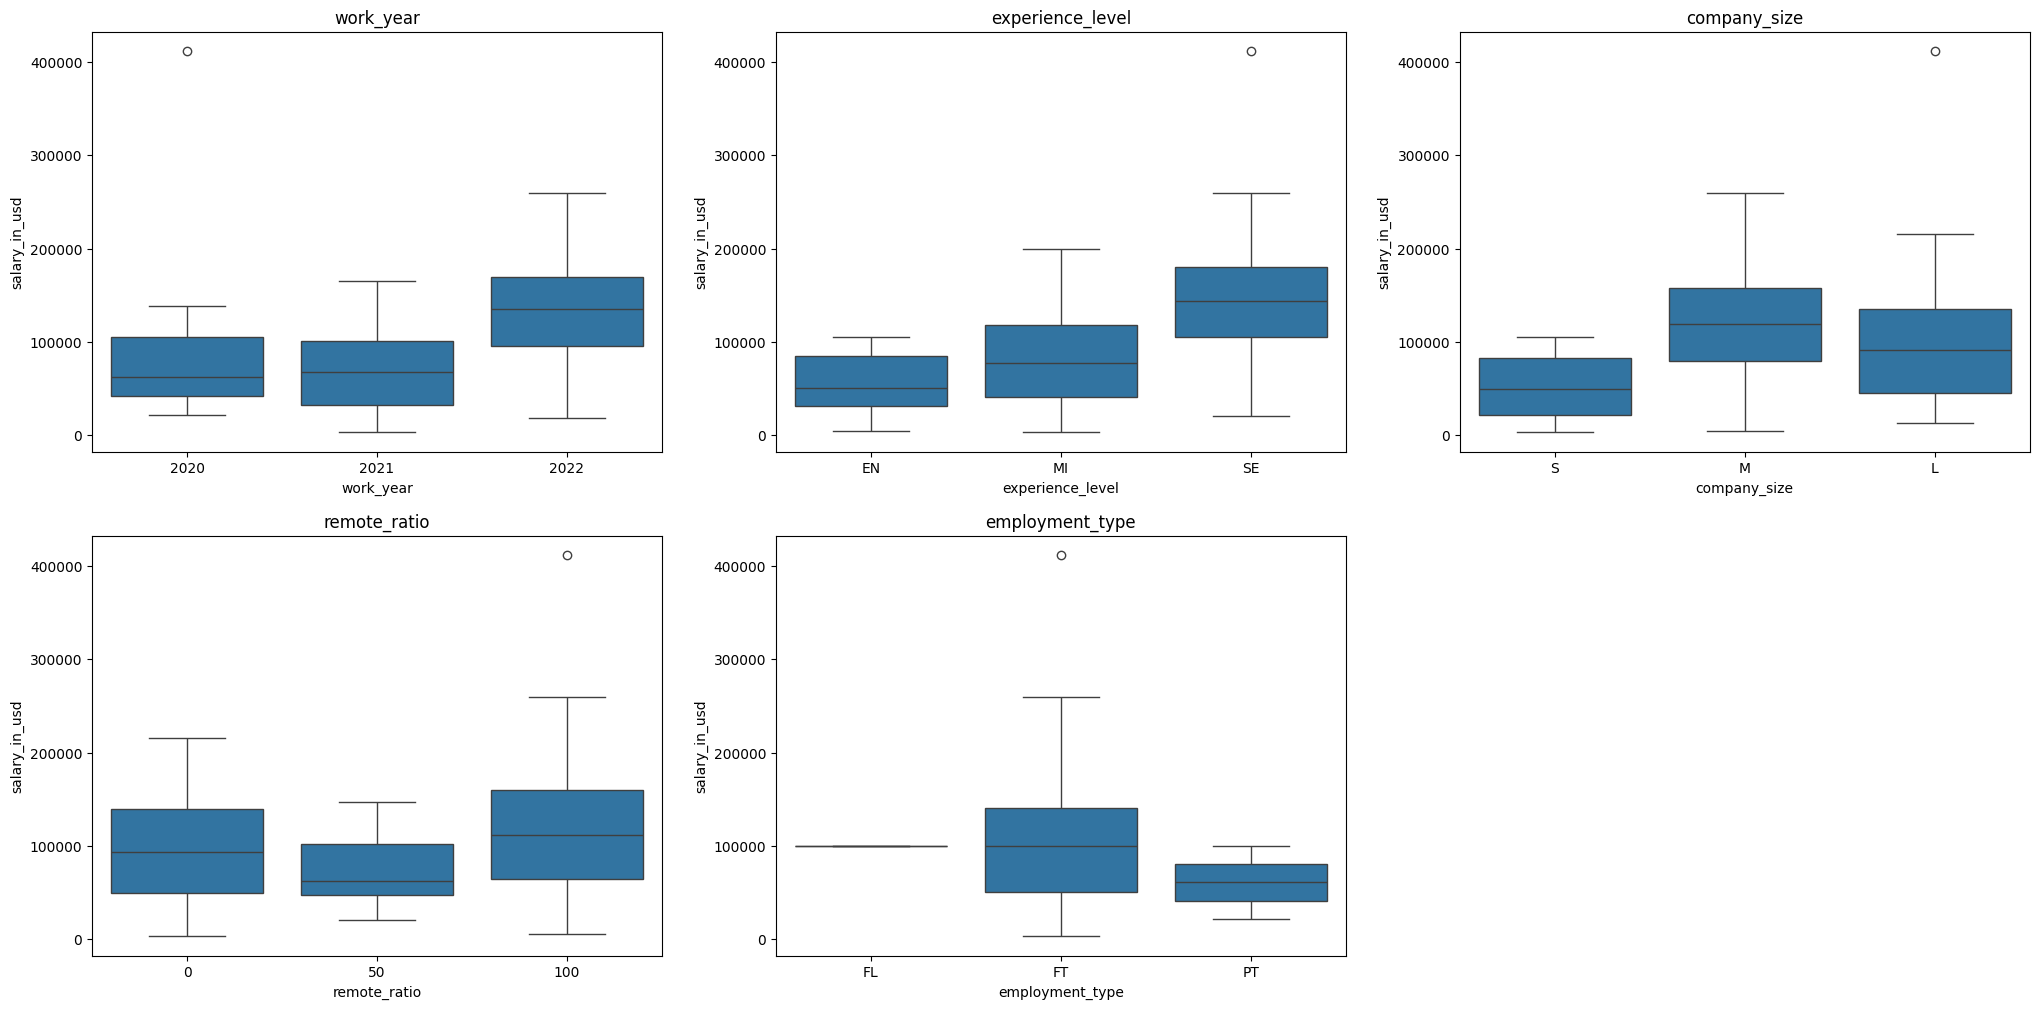

In [10]:
factors = ['work_year', 'experience_level', 'company_size', 'remote_ratio',         
  'employment_type'] 
orders = {'experience_level': ['EN', 'MI', 'SE'], 'company_size': ['S', 'M', 'L']}  
    
fig, axes = plt.subplots(2, 3, figsize=(25, 12))   # подумай, какая сетка нужна для 5 графиков         
for ax, col in zip(axes.flat, factors):                                             
    sns.boxplot(data=ds, x=col, y='salary_in_usd',order=orders.get(col, sorted(ds[col].unique())), ax=ax) 
    ax.set_title(col)
    print(ds[col].value_counts())

fig.delaxes(axes.flat[-1])

На гравиках "work_year" заметно выделяется 2022 год, можем расценить это как рост стоимости оплаты труда специалиста
Медиана у "experience_level" растет от EN к SE. 
У "company_size" так же заметен рост по размеру компании, но среднии компании платет больше крупных 
У "remote_ratio" наблюдается просадку у значения 50 и небольшой рост по сравнению с 0
У "employment_type" если проверить слишком мало значений для FL а большой перекос по кол-ву наблюдений для FT 

Сформулируем гипотезу: 
- H₀: зарплаты DS во все годы одинаковые (распределения / средние равны).           
- H₁: хотя бы в одном году зарплата отличается. 

In [11]:
# функция для принятия решения о нормальности
def decision_normality(p):
    print('p-value = {:.4g}'.format(p))
    if p <= alpha:
        print('p-значение меньше, чем заданный уровень значимости {:.4g}. Распределение отлично от нормального'.format(alpha))
    else:
        print('p-значение больше, чем заданный уровень значимости {:.4g}. Нет оснований отвергнуть гипотезу о нормальности распределения'.format(alpha))


# функция для принятия решения об отклонении нулевой гипотезы
def decision_hypothesis(p):
    print('p-value = {:.4g}'.format(p))
    if p <= alpha:
        print('p-значение меньше, чем заданный уровень значимости {:.4g}. Отвергаем нулевую гипотезу в пользу альтернативной.'.format(alpha))
    else:
        print('p-значение больше, чем заданный уровень значимости {:.4g}. У нас нет оснований отвергнуть нулевую гипотезу.'.format(alpha))


<h2>Рост зарплат DS по годам </h2>

In [12]:
for year in [2020, 2021, 2022]:                                                     
    sample = ds.loc[ds['work_year'] == year, 'salary_in_usd'] 
    print(f'--- {year} ---')
    result = stats.shapiro(sample)  
    decision_normality(result[1])

--- 2020 ---
p-value = 1.717e-06
p-значение меньше, чем заданный уровень значимости 0.05. Распределение отлично от нормального
--- 2021 ---
p-value = 0.1072
p-значение больше, чем заданный уровень значимости 0.05. Нет оснований отвергнуть гипотезу о нормальности распределения
--- 2022 ---
p-value = 0.6762
p-значение больше, чем заданный уровень значимости 0.05. Нет оснований отвергнуть гипотезу о нормальности распределения


 Распределение в 2020 году отличается от нормального, поэтому ANOVA применять нельзя. Используем непараметрический критерий Краскела–Уоллиса для трёх независимых выборок. 

In [13]:
salary_2020 = ds.loc[ds['work_year'] == 2020, 'salary_in_usd']                      
salary_2021 = ds.loc[ds['work_year'] == 2021, 'salary_in_usd']                      
salary_2022 = ds.loc[ds['work_year'] == 2022, 'salary_in_usd'] 

_, p = stats.kruskal(salary_2020, salary_2021, salary_2022)                         
decision_hypothesis(p) 

p-value = 6.625e-08
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу в пользу альтернативной.


Сформулируем гипотезу:
- H₀: зарплата в году N не меньше, чем в году N+1;                                  
- H₁: зарплата в году N меньше, чем в году N+1 (то есть был рост). 

In [14]:
print('--- 2020 vs 2021 ---')                                                       
_, p_2020_2021 = stats.mannwhitneyu(salary_2020, salary_2021, alternative='less')             
decision_hypothesis(p_2020_2021)

--- 2020 vs 2021 ---
p-value = 0.7054
p-значение больше, чем заданный уровень значимости 0.05. У нас нет оснований отвергнуть нулевую гипотезу.


In [15]:
print('--- 2021 vs 2022 ---')                                                       
_, p_2021_2022 = stats.mannwhitneyu(salary_2021, salary_2022, alternative='less')             
decision_hypothesis(p_2021_2022)

--- 2021 vs 2022 ---
p-value = 7.599e-08
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу в пользу альтернативной.


In [16]:
from statsmodels.stats.multitest import multipletests
p_values = [p_2020_2021, p_2021_2022]    
reject, p_corrected, _, _ = multipletests(p_values, alpha=alpha,                    
                                          method='bonferroni')                                                                
print(p_corrected, reject)


[1.00000000e+00 1.51978058e-07] [False  True]


In [17]:
medians = ds.groupby('work_year')['salary_in_usd'].median()                         
growth = pd.DataFrame({                                                             
      'Медиана, $': medians,                                                          
      'Рост, $': medians.diff(),                                                      
      'Рост, %': (medians.pct_change() * 100).round(1)                                
})                                                                                  
growth

,"Медиана, $","Рост, $","Рост, %"
work_year,,,
2020,62726.0,NaN,NaN
2021,67233.5,4507.5,7.2
2022,135000.0,67766.5,100.8


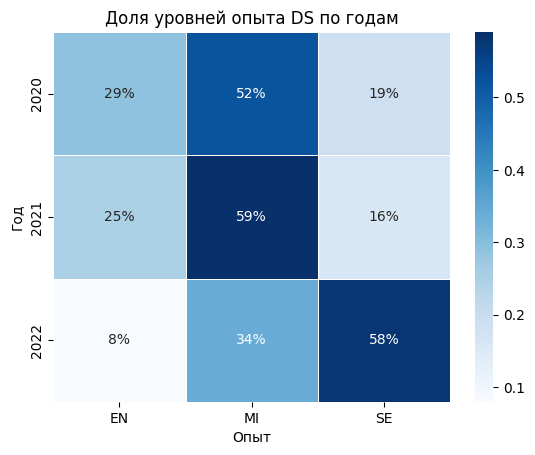

In [18]:
cross_tab = pd.crosstab(ds['work_year'], ds['experience_level'], normalize='index').round(2)
ax = sns.heatmap(cross_tab, annot=True, linewidth=.5, fmt='.0%', cmap="Blues")
ax.set(xlabel='Опыт', ylabel='Год')
plt.title('Доля уровней опыта DS по годам')
plt.show()

Критерий Краскела–Уоллиса показал, что зарплаты DS в 2020–2022 годах статистически значимо различаются (p = 6.6e-08 < α = 0.05).

Парные сравнения (критерий Манна–Уитни, односторонний, с поправкой Бонферрони):
- 2020 → 2021: p_corr = 1.0; медиана 62.7k USD → 67.2k USD (+4.5k USD, +7.2%), различие **статистически не значимо**
- 2021 → 2022: p_corr = 1.5e-07; медиана 67.2k USD → 135k USD (+67.8k USD, **+100.8%**), рост **статистически значим**

**Ответ HR:** ежегодного роста зарплат не наблюдается. В 2020–2021 годах уровень зарплат был стабильным, **но** в 2022 году произошёл резкий скачок: медианная зарплата DS выросла примерно вдвое.

**Оговорка:** в 2022 году заметно изменился состав выборки: доля Senior-специалистов выросла с 16% до 58%, а доля Junior (EN) упала с 25% до 8%. Значительная часть роста медианы может объясняться тем, что в данных 2022 года больше опытных специалистов, а не только реальным ростом рынка.

<h2>DS vs DE в 2022 году</h2>

In [19]:
 # work_year == 2022
db22 = data[data['work_year'] == 2022] 
db_ds=db22[db22['job_title'] == 'Data Scientist']
db_de=db22[db22['job_title'] == 'Data Engineer']

print(db22.shape)
print(db_ds.shape)
print(db_de.shape)

(278, 9)
(65, 9)
(79, 9)


In [20]:
db_ds_med = db_ds['salary_in_usd'].median()
db_de_med = db_de['salary_in_usd'].median()
print(db_ds_med)
print(db_de_med)

135000.0
115000.0


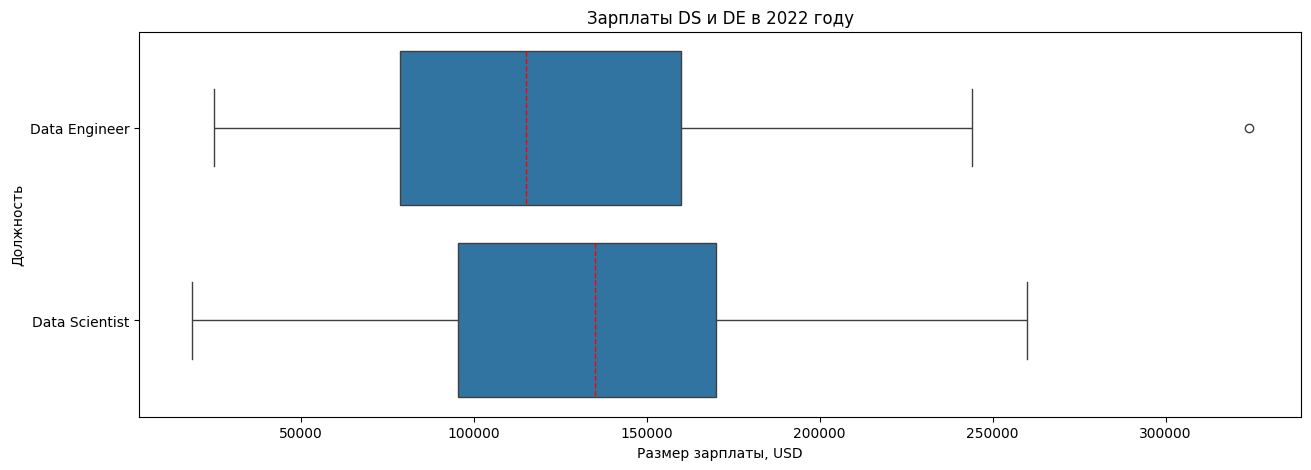

In [21]:
bxdb = db22[db22['job_title'].isin(['Data Scientist', 'Data Engineer'])] 
fig, ax = plt.subplots(figsize=(15, 5))

sns.boxplot(bxdb, x='salary_in_usd',  y='job_title', ax=ax, orient='h', medianprops={"color": "red", "linestyle": '--'})
ax.set(xlabel='Размер зарплаты, USD')
ax.set(ylabel='Должность')
ax.set_title('Зарплаты DS и DE в 2022 году')

plt.show()

In [22]:
sample_db_ds = db_ds['salary_in_usd'] 
print('--- Data Scientist ---') 
result_ds = stats.shapiro(sample_db_ds)  
decision_normality(result_ds[1])

sample_db_de = db_de['salary_in_usd'] 
print('--- Data Engineer ---') 
result_de = stats.shapiro(sample_db_de)  
decision_normality(result_de[1])


--- Data Scientist ---
p-value = 0.6762
p-значение больше, чем заданный уровень значимости 0.05. Нет оснований отвергнуть гипотезу о нормальности распределения
--- Data Engineer ---
p-value = 0.006595
p-значение меньше, чем заданный уровень значимости 0.05. Распределение отлично от нормального


Сформулируем гипотезу: 
  - H₀: распределения зарплат DS и DE одинаковы.                                                                                     
  - H₁: распределения различаются.  

In [23]:
print('--- DS vs DE ---')                                                       
_, p_ds_de = stats.mannwhitneyu(sample_db_ds, sample_db_de, alternative='two-sided')  
decision_hypothesis(p_ds_de)

--- DS vs DE ---
p-value = 0.3194
p-значение больше, чем заданный уровень значимости 0.05. У нас нет оснований отвергнуть нулевую гипотезу.


**Вывод:**

Выбран критерий Манна–Уитни: группы две, они независимы, признак количественный, и одна из групп распределена не нормально (DE, Шапиро p = 0.0066).

Результат: p = 0.3194 > α = 0.05 → нет оснований отвергнуть H₀.

Медианы зарплат: 135 000 USD у Data Scientist и 115 000 USD у Data Engineer. Разница в 20 000 USD на глаз казалась значимой, но тест не выявил статистически значимых различий.

**Ответ HR:** по данным 2022 года нельзя утверждать, что зарплаты DS и DE различаются: разница медиан в 20 000 USD укладывается в обычный разброс зарплат внутри групп.

**Оговорка:** «различие не доказано» не означает «зарплаты одинаковые». Разброс внутри групп большой, а выборки небольшие (65 DS и 79 DE), поэтому реальная разница может существовать, но наших данных недостаточно, чтобы её надёжно обнаружить.

<h2>Зарплата DS и размер компании</h2>

In [24]:
data_agg = ds.groupby('company_size')['salary_in_usd'].describe().round(2)
print('Заработная плата от размера компании')
data_agg

Заработная плата от размера компании


,count,mean,std,min,25%,50%,75%,max
company_size,,,,,,,,
L,43.0,102743.42,73254.10,13400.0,45240.5,90734.0,135000.0,412000.0
M,66.0,120080.58,56347.79,4000.0,80000.0,119529.5,157500.0,260000.0
S,21.0,51925.76,33216.29,2859.0,21669.0,49268.0,82500.0,105000.0


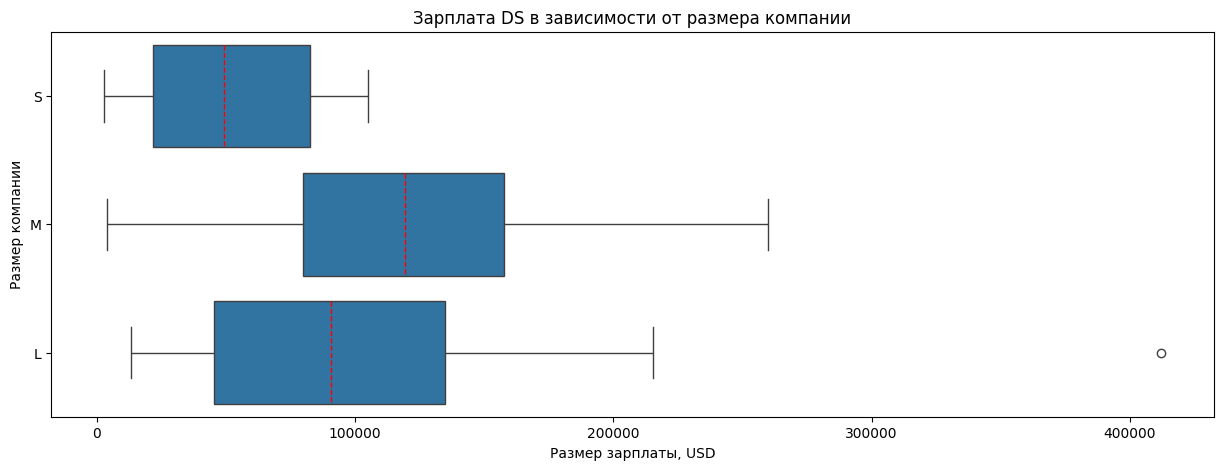

In [25]:
order=['S', 'M', 'L']
fig, ax = plt.subplots(figsize=(15, 5))

sns.boxplot(ds, x='salary_in_usd',  y='company_size', orient='h',order = order, ax=ax, medianprops={"color": "red", "linestyle": '--'})
ax.set(xlabel='Размер зарплаты, USD')
ax.set(ylabel='Размер компании')
ax.set_title('Зарплата DS в зависимости от размера компании')

plt.show()

Сформулируем гипотезу: 
  - H₀: распределение зарплат DS не зависит от размера компании.                                                                                     
  - H₁: хотя бы одна группа отличается от остальных.  

In [26]:
for size in ['S', 'M', 'L']:
    sample = ds.loc[ds['company_size'] == size, 'salary_in_usd']
    print(f'--- Company {size} ---')
    result = stats.shapiro(sample)  
    decision_normality(result[1])
     

--- Company S ---
p-value = 0.189
p-значение больше, чем заданный уровень значимости 0.05. Нет оснований отвергнуть гипотезу о нормальности распределения
--- Company M ---
p-value = 0.8965
p-значение больше, чем заданный уровень значимости 0.05. Нет оснований отвергнуть гипотезу о нормальности распределения
--- Company L ---
p-value = 3.868e-05
p-значение меньше, чем заданный уровень значимости 0.05. Распределение отлично от нормального


In [27]:
ds_m = ds.loc[ds['company_size'] == 'M', 'salary_in_usd']                      
ds_l = ds.loc[ds['company_size'] == 'L', 'salary_in_usd']                      
ds_s = ds.loc[ds['company_size'] == 'S', 'salary_in_usd'] 

# Выполнение теста Краскела — Уоллиса
_, p = stats.kruskal(ds_m, ds_l, ds_s)
decision_hypothesis(p)

p-value = 1.15e-05
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу в пользу альтернативной.


In [28]:
display(pd.crosstab(ds['company_size'], ds['work_year'], normalize='index').round(2))                                              
display(pd.crosstab(ds['company_size'], ds['experience_level'], normalize='index').round(2)) 

work_year,2020,2021,2022
company_size,,,
L,0.16,0.53,0.30
M,0.06,0.17,0.77
S,0.48,0.48,0.05


experience_level,EN,MI,SE
company_size,,,
L,0.14,0.51,0.35
M,0.14,0.38,0.48
S,0.33,0.57,0.10


In [29]:
_, p_S_M = stats.mannwhitneyu(ds_s, ds_m, alternative='two-sided')                                                                   
_, p_M_L = stats.mannwhitneyu(ds_m, ds_l, alternative='two-sided')                                                                   
_, p_S_L = stats.mannwhitneyu(ds_s, ds_l, alternative='two-sided')             

pairs = ['S vs M', 'S vs L', 'M vs L']                                                                                             
p_values = [p_S_M, p_S_L, p_M_L]

reject, p_corrected, _, _ = multipletests(p_values, alpha=alpha, method='bonferroni')

for pair, p_raw, p_corr in zip(pairs, p_values, p_corrected):                                                                      
    print(f'--- {pair} ---')                                                                                                       
    print('сырое p-value = {:.4g}'.format(p_raw))                                                                                  
    decision_hypothesis(p_corr)                                                                                                    
    print() 

--- S vs M ---
сырое p-value = 2.451e-06
p-value = 7.354e-06
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу в пользу альтернативной.

--- S vs L ---
сырое p-value = 0.002612
p-value = 0.007837
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу в пользу альтернативной.

--- M vs L ---
сырое p-value = 0.04829
p-value = 0.1449
p-значение больше, чем заданный уровень значимости 0.05. У нас нет оснований отвергнуть нулевую гипотезу.



**Вывод:**

Выбран **критерий Краскела–Уоллиса**: 3 независимые группы, признак количественный, и одна из групп (L, Шапиро p = 3.9e-05) не распределена нормально.

Результат: p = 1.15e-05 < α = 0.05 → отвергаем H₀, хотя бы одна группа отличается от остальных.

Медианы зарплат DS:
- S (маленькие): 49 268 USD
- M (средние): 119 530 USD
- L (крупные): 90 734 USD

Попарное сравнение **Манна–Уитни** с поправкой Бонферрони:
- S vs M: p_corr = 7.4e-06 → различаются
- S vs L: p_corr = 0.0078 → различаются
- M vs L: p_corr = 0.145 → различие не доказано

На графике медиана у средних компаний выше, чем у крупных, но тест это различие не подтвердил.

Итог: S отличается от обеих групп, а M и L между собой статистически неразличимы.

**Ответ HR:** маленькие компании платят DS меньше, чем средние и крупные, а между средними и крупными значимой разницы нет.

**Оговорка:** группы несопоставимы по составу. Данные по маленьким компаниям почти целиком из 2020–2021 годов (5% из 2022) и содержат только 10% senior, а по средним — 77% из 2022 года и 48% senior. Поэтому разница в зарплатах может частично объясняться годом и опытом, а не самим размером компании.

<h2>Связь должности и размера компании (χ²)</h2>

company_size,L,M,S
job_title,,,
Data Engineer,34,81,6
Data Scientist,43,66,21


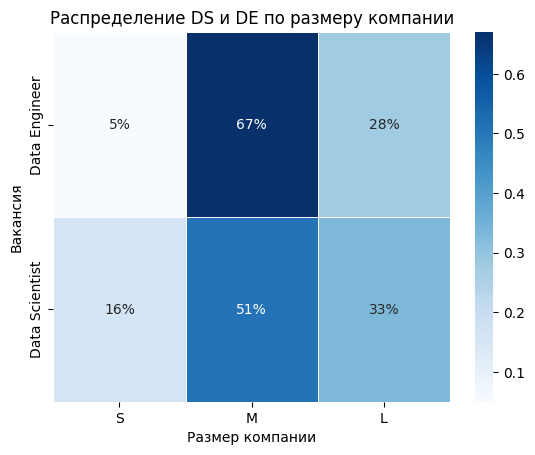

In [30]:
# 5.1
data_ds_de = data[data['job_title'].isin(['Data Scientist', 'Data Engineer'])] 
# 5.2
cross_tab = pd.crosstab(data_ds_de['job_title'], data_ds_de['company_size'])
display(cross_tab)
# 5.3
h_cross_tab = pd.crosstab(data_ds_de['job_title'], data_ds_de['company_size'], normalize='index').round(2)
ax = sns.heatmap(h_cross_tab[['S', 'M', 'L']], annot=True, linewidth=.5, fmt='.0%', cmap="Blues")
ax.set(xlabel='Размер компании', ylabel='Вакансия')
plt.title('Распределение DS и DE по размеру компании')
plt.show()

Сформулируем гипотезу: 
  - H₀: Должность не зависит от размера компании                                                                                    
  - H₁: должность и размер компании связаны 

In [31]:
chi2, p_chi2, dof, expected = stats.chi2_contingency(cross_tab)
print('χ² = {:.4g}, степеней свободы = {}'.format(chi2, dof))                                                                      
decision_hypothesis(p_chi2)                                  

χ² = 10.61, степеней свободы = 2
p-value = 0.004975
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу в пользу альтернативной.


In [32]:
expected_df = pd.DataFrame(expected, index=cross_tab.index, columns=cross_tab.columns).round(1)                                    
display(expected_df) 

company_size,L,M,S
job_title,,,
Data Engineer,37.1,70.9,13.0
Data Scientist,39.9,76.1,14.0


 Самая маленькая ожидаемая частота — 13.0 (DE в маленьких компаниях). Это больше 5, значит, условие выполнено и результату χ² можно 
  доверять.

In [33]:
# Для наглядности о разнице
display(cross_tab - expected_df) 

company_size,L,M,S
job_title,,,
Data Engineer,-3.1,10.1,-7.0
Data Scientist,3.1,-10.1,7.0


**Вывод:**

Использован **критерий χ² (хи-квадрат)**: оба признака категориальные (должность и размер компании), проверяем, связаны ли они между собой. Условие применимости выполнено: минимальная ожидаемая частота = 13 ≥ 5.

Результат: χ² = 10.61, p = 0.005 < α = 0.05 → отвергаем H₀, должность и размер компании связаны.

- **Data Engineer** чаще работают в **средних** компаниях: 67% против 51% у DS (на 10 человек больше, чем ожидалось бы при независимости).
- **Data Scientist** чаще работают в **маленьких** компаниях: 16% против 5% у DE (на 7 человек больше ожидаемого).
- В **крупных** компаниях доли близки: 28% у DE и 33% у DS.

**Ответ HR:** да, связь есть. Data Engineer заметно чаще встречаются в средних компаниях, а Data Scientist — в маленьких. В крупных компаниях обе должности представлены примерно одинаково.

**Оговорка:** χ² показывает только то, что связь **не случайна**. Он не говорит ни о её силе, ни о причинах. Например, нельзя утверждать, что маленькие компании специально предпочитают DS: возможно, у них просто нет объёма данных, ради которого нужен отдельный инженер.

<h2>Шаг 6: Data Scientist в 2022 году получали больше 100 000 USD в год?</h2>

Сформулируем гипотезу:

- H₀: Data Scientist в 2022 году в среднем получали 100 000 USD в год или меньше
- H₁: Data Scientist в 2022 году в среднем получали больше 100 000 USD в год

In [34]:
sample_sl_ds = db_ds['salary_in_usd'] 
print('--- Data Scientist ---') 
print('Медиана: ${:,.0f}'.format(sample_sl_ds.median()))
print('Среднее: ${:,.0f}'.format(sample_sl_ds.mean()))
print('Стандартное отклонение: ${:,.0f}'.format(sample_sl_ds.std()))
print('--- --- --- ---') 
result_sl = stats.shapiro(sample_sl_ds)  
decision_normality(result_sl[1])

--- Data Scientist ---
Медиана: $135,000
Среднее: $131,367
Стандартное отклонение: $55,785
--- --- --- ---
p-value = 0.6762
p-значение больше, чем заданный уровень значимости 0.05. Нет оснований отвергнуть гипотезу о нормальности распределения


**Прогноз:** результат будет значимым. Среднее (≈ 131 000 USD) выше 100 000 USD примерно на 31 000 USD, а стандартная ошибка среднего при n = 65 всего около 7 000 USD, то есть отличие примерно в 4.5 раза больше шума. В отличие от сравнения DS и DE, здесь мы сравниваем выборку с фиксированным числом, поэтому учитывается шум только одной выборки.

In [35]:
result_t = stats.ttest_1samp(sample_sl_ds, popmean = 100_000, alternative = 'greater')
# print(stats.ttest_1samp(sample_sl_ds, popmean = 100_000, alternative = 'greater'))

In [36]:
print('t = {:.4g}, степеней свободы = {}'.format(result_t.statistic, len(sample_sl_ds) - 1)) 
decision_hypothesis(result_t.pvalue)   

t = 4.533, степеней свободы = 64
p-value = 1.303e-05
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу в пользу альтернативной.


In [37]:
# Двусторонний тест
result_t2 = stats.ttest_1samp(sample_sl_ds, popmean=100_000, alternative='two-sided')
# Получаем интервал
ci = result_t2.confidence_interval()
print('95% ДИ для средней: ${:,.0f} — ${:,.0f}'.format(ci.low, ci.high))

95% ДИ для средней: $117,544 — $145,190


**Вывод:**

Выбран **одновыборочный t-критерий**: одна выборка, её среднее сравнивается с заданным числом (100 000 USD от HR), распределение зарплат DS в 2022 году не отличается от нормального (Шапиро p = 0.6762).

Описательные статистики (n = 65):
- Медиана: 135 000 USD
- Среднее: 131 367 USD
- Стандартное отклонение: 55 785 USD

Результат (односторонний тест): t = 4.533, p = 1.3e-05 < α = 0.05 → отвергаем H₀.

95% доверительный интервал для средней зарплаты: 117 544 USD — 145 190 USD. Значение 100 000 USD лежит левее всего интервала, поэтому средняя зарплата выше 100 000 USD как минимум примерно на 17 500 USD.

**Ответ HR:** да, в среднем Data Scientist в 2022 году получали больше 100 000 USD в год.

**Оговорка:**
- Тест проверяет среднее, а не каждого сотрудника. Разброс большой (стандартное отклонение ≈ 55 785 USD), и в выборке есть DS с зарплатой ниже 100 000 USD (например, 90 000 USD). Поэтому нельзя сказать, что каждый специалист получает больше 100 000 USD.
- В 2022 году 58% DS в выборке — senior (в 2020-м было 16%). Высокая средняя отчасти объясняется большой долей опытных специалистов, поэтому переносить вывод на всех DS можно только с осторожностью.

<h2>Шаг 7: Итоговые выводы</h2>

**1. Какие факторы влияют на зарплату Data Scientist**

- **Год** — подтверждено тестами (шаг 2): в 2020–2021 годах зарплаты стабильны, а в 2022 году медиана выросла примерно вдвое (с 67.2k до 135k USD).
- **Размер компании** — подтверждено тестами (шаг 4): в маленьких компаниях DS получают значимо меньше (медиана 49 268 USD), чем в средних (119 530 USD) и крупных (90 734 USD). Средние и крупные компании статистически неразличимы.
- **Опыт** (experience_level) — на EDA медиана заметно растёт от EN к SE, и этот фактор частично объясняет эффекты года и размера компании. Отдельным тестом мы его не проверяли.
- **Должность DS или DE** (шаг 3) — значимой разницы в зарплатах в 2022 году не найдено.
- Не проверяли: remote_ratio (на EDA видна просадка при 50%, но тестом это не подтверждалось) и employment_type (127 из 130 DS работают полный день, по PT и FL всего 2 и 1 наблюдение — для теста этого недостаточно).

**2. Ответы на вопросы HR**

1. **Растут ли зарплаты DS из года в год?** Ежегодного роста нет: между 2020 и 2021 годом значимых изменений нет, а в 2022 году произошёл резкий скачок (медиана примерно вдвое выше). Часть скачка объясняется большей долей senior в данных 2022 года.
2. **Различаются ли зарплаты DS и DE в 2022 году?** Статистически значимой разницы нет (p = 0.32), хотя медиана у DS выше на 20 000 USD.
3. **Зависит ли зарплата DS от размера компании?** Да: маленькие компании платят меньше, чем средние и крупные; между средними и крупными значимой разницы нет.
4. **Связана ли должность (DS или DE) с размером компании?** Да (χ², p = 0.005): DE чаще работают в средних компаниях, DS — в маленьких.
5. **Получали ли DS в 2022 году больше 100 000 USD?** В среднем да: средняя зарплата 131 367 USD, 95% доверительный интервал 117 544 — 145 190 USD (p = 1.3e-05).

**3. Какие тесты применены и когда**

| Ситуация | Нормальное распределение | Не нормальное | Где применяли |
|---|---|---|---|
| 1 выборка и заданное число | одновыборочный t-критерий | критерий знаковых рангов Уилкоксона | шаг 6 (t-критерий) |
| 2 независимые выборки | t-критерий для независимых выборок (Стьюдента или Уэлча) | критерий Манна–Уитни | шаг 3; попарные сравнения в шагах 2 и 4 |
| 3 и более независимых выборок | однофакторный дисперсионный анализ (ANOVA) | критерий Краскела–Уоллиса | шаги 2 и 4 |
| 2 категориальных признака | критерий χ² (нормальность не нужна) | — | шаг 5 |

- Нормальность проверяли **критерием Шапиро–Уилка**. Если хотя бы одна группа распределена не нормально, выбирали непараметрический тест.
- При нескольких попарных сравнениях применяли **поправку Бонферрони**: чем больше сравнений, тем выше шанс случайно получить «значимый» результат, поэтому каждое p-value умножается на число сравнений.
- Для χ² проверяли условие применимости: все ожидаемые частоты не меньше 5.

**4. Общие оговорки**

- **Состав выборки.** Доля senior сильно различается между группами: 58% в 2022 году против 16% в 2020-м, 10% в маленьких компаниях против 48% в средних. Поэтому эффекты года и размера компании частично объясняются опытом — это смешивающий фактор, который мы не отделяли.
- **Данные наблюдательные**, а не результат эксперимента. Тесты показывают связь и различия, но не причину. Корректнее говорить «в маленьких компаниях зарплаты ниже», а не «маленькие компании платят меньше из-за своего размера».
- **Небольшие выборки** (от 21 до 79 наблюдений в группе) и большой разброс зарплат. Отсутствие значимости (DS и DE, средние и крупные компании) не доказывает, что группы одинаковые.
- **Что можно сделать дальше:** проверить влияние опыта отдельным тестом и сравнивать группы внутри одного уровня опыта (например, только senior), чтобы отделить эффекты года и размера компании от опыта.